# 02 最小二乘法 Least-Square(LS)

## 1. 算法介绍

目标：找到一条直线 y = ax + b，来拟合已知的n个(x,y)数据点。从而得到模型参数估计。

方法：让所有数据点到预测值之间的“误差平方和”最小的那条直线，就是最小二乘意义下的最佳直线。

理由：残差$ e_i=y_i-\hat y_i $​直接加正误差和负误差会互相抵消。于是求平方和。

线性回归除了最小二乘法外还有LASSO回归，岭回归等多种算法。

## 2. 数学原理

残差：

$$ e_i=y_i-\hat y_i $$

也就是：

$$ e_i=y_i-(a+bx_i) $$

最小二乘法目标：

$$ \boxed{ S(a,b)=\sum_{i=1}^{n}[y_i-(a+bx_i)]^2 } $$

寻找
$ a,b $
使得：
$ S(a,b) $
尽可能小。所以叫最小二乘。

如果一个函数在某个内部点取得极小值，那么它的一阶导数应该为 0。

原函数：

$$ S=\sum_{i=1}^{n}(y_i-a-bx_i)^2 $$

对 \(a\) 求偏导：

$$ \frac{\partial S}{\partial a} = -2\sum_{i=1}^{n}(y_i-a-bx_i) $$

令他等于0：

$$ \sum(y_i-a-bx_i)=0 $$

展开：

$$ \sum y_i-na-b\sum x_i=0 $$

因此：

$$ na+b\sum x_i=\sum y_i $$

两边除以 \(n\)：

$$ a+b\bar x=\bar y $$

所以：

$$ \boxed{ a=\bar y-b\bar x } $$

对 \(b\) 求偏导：

$$ \frac{\partial S}{\partial b} = -2\sum x_i(y_i-a-bx_i) $$

令：

$$ \frac{\partial S}{\partial b}=0 $$

得到：

$$ \sum x_i(y_i-a-bx_i)=0 $$

整理后，可以得到：

$$ \boxed{ b= \frac{\sum(x_i-\bar x)(y_i-\bar y)} {\sum(x_i-\bar x)^2} } $$

因此最终得到：

$$ \boxed{ \hat y=a+bx } $$

斜率：

$$ b= \frac{\sum(x_i-\bar x)(y_i-\bar y)} {\sum(x_i-\bar x)^2} $$

可以拆成上下两部分。

分子：

$$ \sum(x_i-\bar x)(y_i-\bar y) $$

实际上和 协方差有关。

分母：

$$ \sum(x_i-\bar x)^2 $$

实际上和 \(X\) 的方差有关。

所以可以理解成：

$$ \boxed{ \text{回归系数} \approx \frac{\text{X与Y共同变化程度}} {\text{X自身变化程度}} } $$

进一步可以写成：

$$ \boxed{ b=\frac{\operatorname{Cov}(X,Y)} {\operatorname{Var}(X)} } $$

这里如果使用的是总体/样本协方差和方差的同一归一化约定，比例关系成立。

这个公式非常值得记住，因为它把：相关性 → 协方差 → 回归 连接了起来。

但现实中通常有很多变量。

比如预测房价：

$$ \text{房价} = \beta_0+ \beta_1\text{面积} +\beta_2\text{房间数} +\beta_3\text{楼层} +\beta_4\text{房龄} $$

这时候使用矩阵会非常方便。

写成：

$$ \boxed{ \mathbf y=X\boldsymbol\beta+\boldsymbol\varepsilon } $$

其中：

$$ \mathbf y= \begin{bmatrix} y_1\\ y_2\\ \vdots\\ y_n \end{bmatrix} $$

设计矩阵：

$$ X= \begin{bmatrix} 1&x_{11}&x_{12}&\cdots&x_{1p}\\ 1&x_{21}&x_{22}&\cdots&x_{2p}\\ \vdots&\vdots&\vdots&&\vdots\\ 1&x_{n1}&x_{n2}&\cdots&x_{np} \end{bmatrix} $$

参数：

$$ \boldsymbol\beta= \begin{bmatrix} \beta_0\\ \beta_1\\ \vdots\\ \beta_p \end{bmatrix} $$

我们希望：

$$ \|\mathbf y-X\boldsymbol\beta\|^2 $$

最小。

也就是：

$$ \boxed{ \min_{\boldsymbol\beta} (\mathbf y-X\boldsymbol\beta)^T (\mathbf y-X\boldsymbol\beta) } $$

求导并令其为 0：

$$ X^TX\hat{\boldsymbol\beta}=X^T\mathbf y $$

这叫：

正规方程（Normal Equation）

如果 \(X^TX\) 可逆：

$$ \boxed{ \hat{\boldsymbol\beta} = (X^TX)^{-1}X^T\mathbf y } $$

这个公式是整个普通最小二乘法（OLS）的核心公式之一。

误差服从正态分布。

那么使用**最大似然估计（MLE）**得到的 \(\beta\)，恰好就是最小二乘估计：

$$ \boxed{ \hat\beta_{MLE}=\hat\beta_{OLS} } $$

## 3. 导入相关库

In [5]:
import numpy as np

## 4. 构造数据

In [6]:
x = np.array([1, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 9])
y = np.array([52, 55, 61, 63, 67, 70, 72, 76, 78, 82, 85, 87, 91, 93, 96])

## 5. 手动实现

In [7]:
x_mean = np.mean(x)
y_mean = np.mean(y)

b = np.sum((x - x_mean) * (y - y_mean))/(np.sum((x - x_mean)**2))
a = y_mean - b * x_mean

print(a,b)

45.84516129032259 5.870967741935483


## 6. 使用 scikit-learn 库实现

In [10]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X1 = x.reshape(-1, 1)

model = LinearRegression()
model.fit(X1, y)
b0 = model.intercept_
b1 = model.coef_[0]

print("截距 b0 =", b0)
print("斜率 b1 =", b1)

截距 b0 = 45.84516129032258
斜率 b1 = 5.870967741935485


## 7. 可视化

<function matplotlib.pyplot.show(close=None, block=None)>

c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 20108 (\N{CJK UNIFIED IDEOGRAPH-4E8C}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 20056 (\N{CJK UNIFIED IDEOGRAPH-4E58}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\c

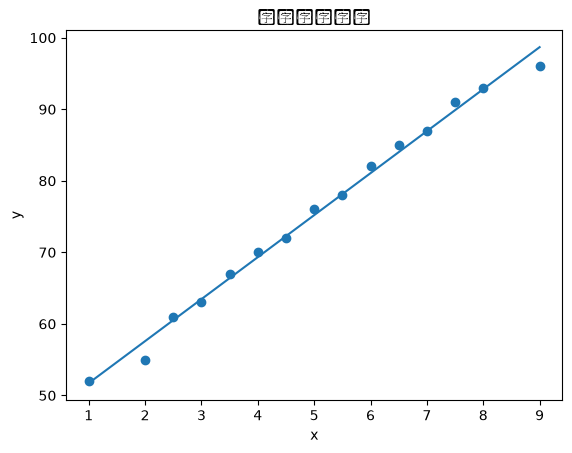

In [14]:
import matplotlib.pyplot as plt

plt.scatter(x,y)
plt.plot(x,a + b*x)
plt.xlabel("x")
plt.ylabel("y")
plt.title("最小二乘回归")
plt.show

## 9. python新知识

1.NumPy数组（np.array([])）可以进行“逐元素运算”，所以可以实现数组减常数。但列表[]不可以

2.对NumPy数组进行运算需要用np.方法

3.平方：**2

4.使用 scikit-learn 库实现训练模型：model.fit(X, Y)